# Assignment 4 - GMM Based Synthetic Sampling

## Imports

Only for Colab

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !cp /content/drive/MyDrive/kaggle.json /content/kaggle.json
# !mkdir -p /root/.config/kaggle
# !cp kaggle.json /root/.config/kaggle
# !chmod 600 /root/.config/kaggle/kaggle.json

In [3]:
import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import kaggle
from kagglehub import KaggleDatasetAdapter

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.cluster import *
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, GridSearchCV

import imblearn
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import *
from imblearn.under_sampling import *
from imblearn.metrics import *

## PART A : Data Exploration

Going through the Kaggle Data Information page, we note the following:
1. The dataset is already processed into numeric values to hide sensitive information (hence no need for encoding).
2. PCA has already been performed and we are given some of its principal components.
3. Two additional features are provided -
a. Time: Time elapsed in seconds since the first transaction
b. Amount: Monetary amount
4. Class contains the binary target labels

Also, as the dataset size is too big, you would have to download from the Kaggle website with your API key

In [4]:
kaggle.api.dataset_download_files('mlg-ulb/creditcardfraud', path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


In [5]:
data = pd.read_csv('data/creditcard.csv')  # load the dataset

In [6]:
data    # display some of its rows

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [7]:
data.describe()  # some statistics on it

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


To see the class imbalance:

Percentage of Positive Class data points: 0.1727485630620034
Percentage of Negative Class data points: 99.82725143693798
Ratio of number of Negative Class to that of Positive Class : 577.8760162601626


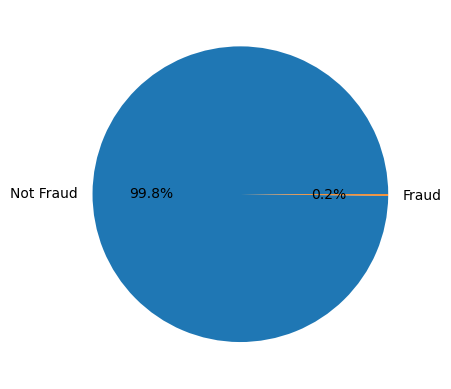

In [8]:
neg_class = data[data['Class'] == 0]
pos_class = data[data['Class'] == 1]
neg_class_count, pos_class_count = data['Class'].value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(data) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(data) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
plt.savefig('images/pie_chart_class_dis.png')
plt.show()

#### Why is this bad?
1. Most of classifiers (like Logistic Regression) is built on the assumption that the dataset is balanced.
2. Standard classification algorithms often perform poorly on such datasets, as they tend to classify most instances as the majority class to achieve high overall accuracy, ignoring the minority class.
3. The usual metrics used for gauging a model's performance, such as Accuracy, Precision, AUC-ROC and F1, are highly senstitive to the class imbalance and may indicate misleading results.

#### What can be done?
We have three options in hand. We can choose either one or more:
1. Process the Dataset
2. Use better models (which is out of scope for our problem statement)
3. Use better metrics

In [9]:
x, y = data.drop(columns=['Class']), data['Class']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, stratify=y)

## Pipeline

In [11]:
def report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from sklearn
    """

    y_test = y_test.to_numpy()
    x = ["Fraud", "Not Fraud"]
    actual_fraud, predict_fraud = y_test[np.where(y_test == 1)[0]], y_pred[np.where(y_test == 1)[0]]
    actual_not_fraud, predict_not_fraud = y_test[np.where(y_test == 0)[0]], y_pred[np.where(y_test == 0)[0]]

    report = {
        "Fraud": {
            "precision": precision_score(actual_fraud, predict_fraud),
            "recall": recall_score(actual_fraud, predict_fraud),
            "f1": f1_score(actual_fraud, predict_fraud),
            "bal_acc": balanced_accuracy_score(actual_fraud, predict_fraud),
            "accuracy": accuracy_score(actual_fraud, predict_fraud),
            "size": len(actual_fraud)
        },
        "Not Fraud": {
            "precision": precision_score(actual_not_fraud, predict_not_fraud),
            "recall": recall_score(actual_not_fraud, predict_not_fraud),
            "f1": f1_score(actual_not_fraud, predict_not_fraud),
            "bal_acc": balanced_accuracy_score(actual_not_fraud, predict_not_fraud),
            "accuracy": accuracy_score(actual_not_fraud, predict_not_fraud),
            "size": len(actual_not_fraud)
        },
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        "roc_curve": roc_curve(y_test, y_pred),
        "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred),
        "avg_p": average_precision_score(y_test, y_pred)
    }
    fraud, not_fraud = report['Fraud'], report['Not Fraud']

    fig, axs = plt.subplots(3, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#D55E00',  # Vermillion
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        if i != 'size':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i.capitalize()} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylabel(f"Log of {i.capitalize()} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report_skelearn.png")
    plt.show()

    cm = ConfusionMatrixDisplay(confusion_matrix=report['confusion_matrix'], display_labels=x[::-1])
    cm.plot()
    plt.savefig(f"images/Confusion_mat_{name}.png")
    plt.show()

    # pr = PrecisionRecallDisplay.from_predictions(y_test, y_pred)
    # pr.plot()
    # plt.savefig(f"images/PR_Curve_{name}.png")
    # plt.show()

    # roc = RocCurveDisplay.from_predictions(y_test, y_pred)
    # roc.plot()
    # plt.savefig(f"images/ROC_Curve_{name}.png")
    # plt.show()

    return report

In [12]:
def imbalanced_report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from imblearn
    """

    report = classification_report_imbalanced(y_test, y_pred,
    labels=[0, 1], target_names=['Not Fraud', 'Fraud'], output_dict=True)
    d = {
        "pre": "Precison", "rec": "Recall",
        "spe": "Specificity", "f1": "F1 Score",
        "geo": "FM Index", "iba": "IBA",
        "sup": "Support", "avg_pre": "Average Precision",
        "avg_rec": "Average Recall", "avg_spe": "Average Specificity",
        "avg_f1": "Average F1 Score", "avg_geo": "Average FM Index",
        "avg_iba": "Average IBA", "total_support": "Total Support"
    }
    better_report = {
        "Fraud": dict(), "Not Fraud": dict(), 
        "Average Precision": 0,"Average Recall": 0,
        "Average Specificity": 0,
        "Average F1 Score": 0,
        "Average FM Index": 0,
        "Average Index Balanced Accuracy": 0,
        "Total Support": 0
    }
    for i in report:
        if i == "Fraud":
            k = report[i]
            for j in k:
                better_report["Fraud"][d[j]] = k[j]
        elif i == "Not Fraud":
            k = report[i]
            for j in k:
                better_report["Not Fraud"][d[j]] = k[j]
        else:
            better_report[d[i]] = report[i]
    fraud, not_fraud = better_report['Fraud'], better_report['Not Fraud']

    fig, axs = plt.subplots(4, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        x = ["Fraud", "Not Fraud"]
        if i != 'Support':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylabel(f"Log of {i} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    axs[k, l].bar(x=["Fraud", "Not Fraud"], height=[np.log(len(pos_class)), np.log(len(neg_class))])
    axs[k, l].set_title("Sample Size Comparison")
    axs[k, l].set_xlabel(f"Class")
    axs[k, l].set_ylabel(f"Log of Size Value")
    for q in range(len(x)):
        axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report.png")
    plt.show()

    return better_report

In [13]:
def classify(data, name, balanced=False, sampler = None):
    """
        The main pipeline code
    """

    # First Standardize the data
    x, y = StandardScaler().fit_transform(data.drop(columns=['Class'])), data['Class']
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25)
    
    pipeline = []
    if sampler is not None:
        pipeline.append(('sampler', sampler))
    if balanced:  # if we want to test with balanced class weights
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs", class_weight='balanced')))
    else:
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs")))
    pipeline = Pipeline(pipeline)

    model = pipeline.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r1 = report_generator(y_pred, y_test, name)
    r2 = imbalanced_report_generator(y_pred, y_test, name)
    
    k = ['precision','recall','f1','bal_acc','mcc','accuracy','roc_auc','avg_p']
    new_r1 = {i: r1[i] for i in k}
    new_r1['positive_likelihood_ratio'] = r1['likelihood_ratios'][0]
    new_r1['negative_likelihood_ratio'] = r1['likelihood_ratios'][1]
    new_r1['name'] = name
    df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    return model, r1, r2, df